In [4]:
"""
import numpy as np

# Sample dataset: [Energy, Speed, Class]
data = np.array([
    [100, 0.8, 'Background'],
    [150, 0.9, 'Signal'],
    [120, 0.85, 'Background'],
    [130, 0.95, 'Signal'],
    [140, 0.92, 'Signal'],
    [110, 0.83, 'Background']
])

# Function to calculate Gini impurity
def gini_impurity(groups, classes):
    # Count all samples at split point
    n_instances = float(sum([len(group) for group in groups]))
    gini = 0.0
    for group in groups:
        size = float(len(group))
        if size == 0:  # Avoid division by zero
            continue
        score = 0.0
        # Score the group based on the score for each class
        for class_val in classes:
            p = [row[-1] for row in group].count(class_val) / size
            score += p * p
        # Weight the group score by its relative size
        gini += (1.0 - score) * (size / n_instances)
    return gini

# Unique classes in the dataset
classes = np.unique(data[:, -1])
"""

"\nimport numpy as np\n\n# Sample dataset: [Energy, Speed, Class]\ndata = np.array([\n    [100, 0.8, 'Background'],\n    [150, 0.9, 'Signal'],\n    [120, 0.85, 'Background'],\n    [130, 0.95, 'Signal'],\n    [140, 0.92, 'Signal'],\n    [110, 0.83, 'Background']\n])\n\n# Function to calculate Gini impurity\ndef gini_impurity(groups, classes):\n    # Count all samples at split point\n    n_instances = float(sum([len(group) for group in groups]))\n    gini = 0.0\n    for group in groups:\n        size = float(len(group))\n        if size == 0:  # Avoid division by zero\n            continue\n        score = 0.0\n        # Score the group based on the score for each class\n        for class_val in classes:\n            p = [row[-1] for row in group].count(class_val) / size\n            score += p * p\n        # Weight the group score by its relative size\n        gini += (1.0 - score) * (size / n_instances)\n    return gini\n\n# Unique classes in the dataset\nclasses = np.unique(data[:, -1

In [5]:
"""

### Evaluating Thresholds for Each Feature:

1. **Sorting Data by Feature Values**:
   - First, for each feature (e.g., `Energy` and `Speed`), sort the data points according to their feature values. 

2. **Potential Thresholds**:
   - Potential thresholds are the values that lie between distinct feature values in the sorted list.
   - For example, if `Energy` values sorted are `[100, 110, 120, 130, 140, 150]`, potential thresholds could be `[105, 115, 125, 135, 145]`.

3. **Evaluating Each Threshold**:
   - For each threshold, divide the dataset into two parts: one where the feature value is less than or equal to the threshold and one where it's greater.
   - Calculate the impurity (e.g., Gini impurity) for each part.
   - Compute the weighted average of these impurities to get the total impurity for that split.
   - The goal is to find the threshold that results in the largest decrease in impurity.

4. **Repeat for Each Feature**:
   - Repeat this process for each feature (`Energy` and `Speed`).
   - Compare the decrease in impurity achieved by the best thresholds for each feature.
   - Choose the feature and its corresponding threshold that gives the maximum decrease in impurity.

### Example with `Energy`:

- Sorted `Energy` values: `[100, 110, 120, 130, 140, 150]`.
- Potential thresholds: `[105, 115, 125, 135, 145]`.
- For `Energy` threshold of `115`, split data into two groups:
  - Group 1: `Energy` <= 115 (contains some background and maybe signal).
  - Group 2: `Energy` > 115 (contains the rest).
- Calculate impurity for each group and the weighted average impurity for the split.
- Repeat for other thresholds `[105, 125, 135, 145]`.

### Example with `Speed`:

- Apply a similar process to `Speed`, with its own sorted values and potential thresholds.
- Calculate impurities for each possible split.

### Choosing the Best Split:

- After evaluating all possible thresholds for all features, choose the split (feature and its threshold) that results in the highest decrease in impurity.
- This becomes the decision criterion at the node of the tree.

In real-world applications, especially with continuous features and large datasets, evaluating every possible threshold can be computationally intensive. Therefore, optimizations and heuristics are often used to efficiently find good, if not optimal, splits.

"""

"\n\n### Evaluating Thresholds for Each Feature:\n\n1. **Sorting Data by Feature Values**:\n   - First, for each feature (e.g., `Energy` and `Speed`), sort the data points according to their feature values. \n\n2. **Potential Thresholds**:\n   - Potential thresholds are the values that lie between distinct feature values in the sorted list.\n   - For example, if `Energy` values sorted are `[100, 110, 120, 130, 140, 150]`, potential thresholds could be `[105, 115, 125, 135, 145]`.\n\n3. **Evaluating Each Threshold**:\n   - For each threshold, divide the dataset into two parts: one where the feature value is less than or equal to the threshold and one where it's greater.\n   - Calculate the impurity (e.g., Gini impurity) for each part.\n   - Compute the weighted average of these impurities to get the total impurity for that split.\n   - The goal is to find the threshold that results in the largest decrease in impurity.\n\n4. **Repeat for Each Feature**:\n   - Repeat this process for each

Best Split: [X1 < 130.000]


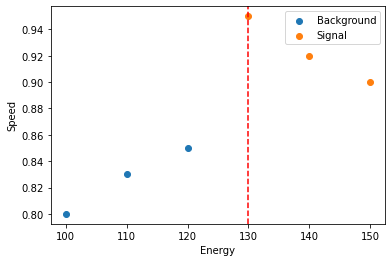

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Sample dataset: [Energy, Speed, Class]
data = np.array([
    [100, 0.8, 'Background'],
    [150, 0.9, 'Signal'],
    [120, 0.85, 'Background'],
    [130, 0.95, 'Signal'],
    [140, 0.92, 'Signal'],
    [110, 0.83, 'Background']
], dtype=object)  # Use 'object' dtype to accommodate mixed types

# Function to calculate Gini impurity
def gini_impurity(groups, classes):
    n_instances = float(sum([len(group) for group in groups]))
    gini = 0.0
    for group in groups:
        size = float(len(group))
        if size == 0:
            continue
        score = 0.0
        for class_val in classes:
            p = [row[-1] for row in group].count(class_val) / size
            score += p * p
        gini += (1.0 - score) * (size / n_instances)
    return gini

# Function to split the dataset
def test_split(index, value, dataset):
    left, right = [], []
    for row in dataset:
        if row[index] < value:
            left.append(row)
        else:
            right.append(row)
    return left, right

# Function to select the best split
def get_split(dataset):
    classes = np.unique(dataset[:, -1])
    b_index, b_value, b_score, b_groups = 999, 999, 999, None
    for index in range(2):  # Only consider the first two columns for splitting
        for row in dataset:
            groups = test_split(index, row[index], dataset)
            gini = gini_impurity(groups, classes)
            if gini < b_score:
                b_index, b_value, b_score, b_groups = index, row[index], gini, groups
    return {'index': b_index, 'value': b_value, 'groups': b_groups}

# Get the best split
split = get_split(data)
print('Best Split: [X%d < %.3f]' % ((split['index'] + 1), float(split['value'])))

# Plotting the data and the split
def plot_data(data, split):
    fig, ax = plt.subplots()
    for class_val in np.unique(data[:, -1]):
        subset = data[data[:, -1] == class_val]
        ax.scatter(subset[:, 0], subset[:, 1], label=str(class_val))
    if split['index'] == 0:
        ax.axvline(x=float(split['value']), color='r', linestyle='--')
    else:
        ax.axhline(y=float(split['value']), color='r', linestyle='--')
    ax.set_xlabel('Energy')
    ax.set_ylabel('Speed')
    ax.legend()
    plt.show()

plot_data(data, split)

